In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
from tqdm import tqdm
import tifffile
from ipywidgets import HBox, VBox

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
Unable to find extension: VK_EXT_swapchain_colorspace
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
from skophys.preprocessing import Vectorizer, UnVectorizer, PercentileFilter

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [3]:
%matplotlib inline

In [4]:
path = "./demo_movie_mcorr.tiff"
movie = tifffile.imread(path)

In [5]:
unvec = UnVectorizer(movie.shape[1:])

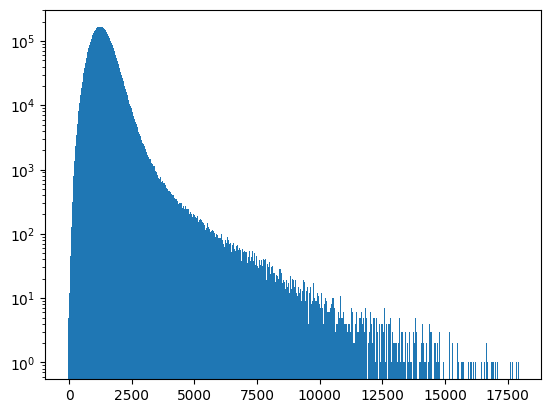

In [6]:
plt.hist(movie.ravel(), bins=1_000)
plt.semilogy()
plt.show()

In [7]:
def mean_psd(y, method='logmexp'):
    """
    Averaging the PSD

    Args:
        y: np.ndarray
             PSD values

        method: string
            method of averaging the noise.
            Choices:
             'mean': Mean
             'median': Median
             'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        mp: array
            mean psd
    """

    if method == 'mean':
        mp = np.sqrt(np.mean(y / 2, axis=-1))
    elif method == 'median':
        mp = np.sqrt(np.median(y / 2, axis=-1))
    else:
        mp = np.log((y + 1e-10) / 2)
        mp = np.mean(mp, axis=-1)
        mp = np.exp(mp)
        mp = np.sqrt(mp)

    return mp

def get_noise_fft(Y, noise_range=[0.25, 0.5], noise_method='logmexp', max_num_samples_fft=3072,
                  opencv=True):
    """Estimate the noise level for each pixel by averaging the power spectral density.

    Args:
        Y: np.ndarray
            Input movie data with time in the last axis

        noise_range: np.ndarray [2 x 1] between 0 and 0.5
            Range of frequencies compared to Nyquist rate over which the power spectrum is averaged
            default: [0.25,0.5]

        noise method: string
            method of averaging the noise.
            Choices:
                'mean': Mean
                'median': Median
                'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        sn: np.ndarray
            Noise level for each pixel
    """
    T = Y.shape[-1]
    # Y=np.array(Y,dtype=np.float64)

    if T > max_num_samples_fft:
        Y = np.concatenate((Y[..., 1:max_num_samples_fft // 3 + 1],
                            Y[..., int(T // 2 - max_num_samples_fft / 3 / 2)
                                          :int(T // 2 + max_num_samples_fft / 3 / 2)],
                            Y[..., -max_num_samples_fft // 3:]), axis=-1)
        T = np.shape(Y)[-1]

    # we create a map of what is the noise on the FFT space
    ff = np.arange(0, 0.5 + 1. / T, 1. / T)
    ind1 = ff > noise_range[0]
    ind2 = ff <= noise_range[1]
    ind = np.logical_and(ind1, ind2)
    # we compute the mean of the noise spectral density s
    if Y.ndim > 1:
        if opencv:
            import cv2
            try:
                cv2.setNumThreads(0)
            except:
                pass
            psdx_list = []
            for y in Y.reshape(-1, T):
                dft = cv2.dft(y, flags=cv2.DFT_COMPLEX_OUTPUT).squeeze()[
                    :len(ind)][ind]
                psdx_list.append(np.sum(1. / T * dft * dft, 1))
            psdx = np.reshape(psdx_list, Y.shape[:-1] + (-1,))
        else:
            xdft = np.fft.rfft(Y, axis=-1)
            xdft = xdft[..., ind[:xdft.shape[-1]]]
            psdx = 1. / T * abs(xdft)**2
        psdx *= 2
        sn = mean_psd(psdx, method=noise_method)

    else:
        xdft = np.fliplr(np.fft.rfft(Y))
        psdx = 1. / T * (xdft**2)
        psdx[1:] *= 2
        sn = mean_psd(psdx[ind[:psdx.shape[0]]], method=noise_method)

    return sn, psdx

In [8]:
sn, psdx = get_noise_fft(movie.transpose(1, 2, 0))

movie /= sn

In [9]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  iw_movie.data[0][:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

HBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [10]:
iw_movie.window_funcs = {"t": (np.mean, 1)}

/home/kushal/repos/fastplotlib/fastplotlib/widgets/image_widget/_widget.py:84: UserWarning: Invalid 'window size' value for function: <function mean at 0x7fd150d91c60>, setting 'window size' = None for this function. Valid values are integers >= 3.
  warn(


In [11]:
filt_movie = PercentileFilter(window_size=5, quantile=5).transform(movie)

In [12]:
iw_movie.set_data(unvec.transform(filt_movie), reset_indices=False)

In [13]:
from sklearn.preprocessing import RobustScaler

In [14]:
ss = RobustScaler()

In [15]:
Y = ss.fit_transform(filt_movie.T).T

In [16]:
iw_movie.set_data(unvec.transform(Y), reset_indices=False)

In [16]:
Y

array([[-0.89419097, -0.89419097, -0.8748388 , ...,  0.2051251 ,
         1.6246736 , -4.1461906 ],
       [-1.6006716 , -1.6006716 , -1.7303635 , ...,  0.22551222,
         2.132441  , -3.8895519 ],
       [-0.7251243 , -0.8608975 , -0.9109863 , ...,  1.7932593 ,
         3.6691647 , -4.0335784 ],
       ...,
       [-0.7038758 , -0.7038758 , -0.63659984, ...,  2.5688431 ,
         2.999742  , -3.1861932 ],
       [-1.1421993 , -1.1421993 , -1.1421993 , ...,  2.2942994 ,
         2.649461  , -3.1933663 ],
       [-1.0373353 , -1.0373353 , -0.56953984, ...,  0.8750072 ,
         2.248134  , -3.2532547 ]], dtype=float32)

In [17]:
Y = Y[:, :-1]

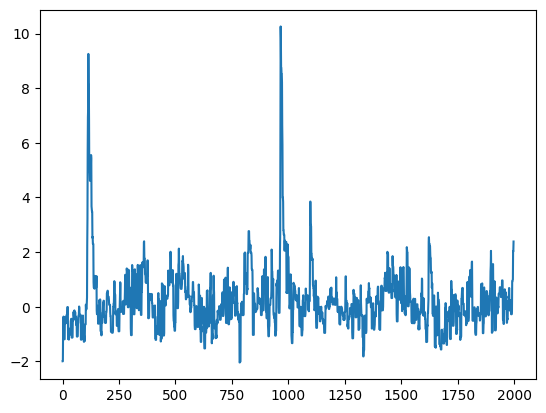

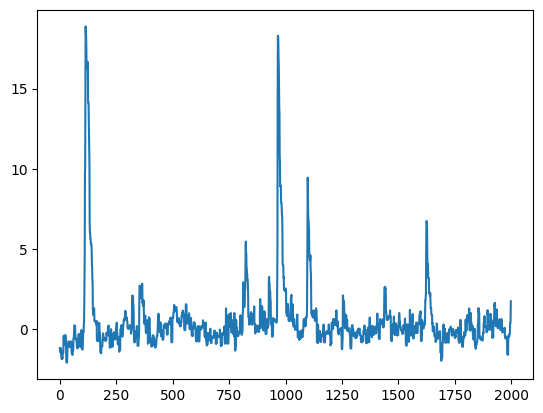

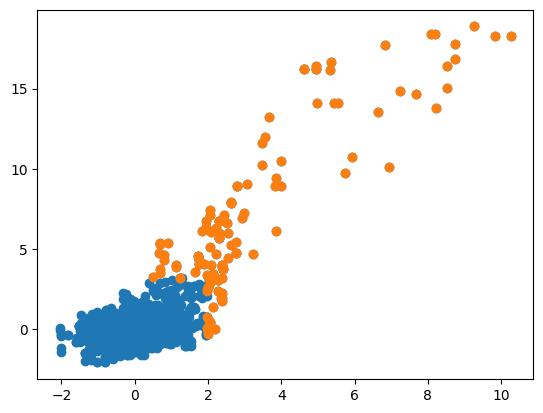

In [101]:
i1 = 2502
i2 = 2510

u = Y[i1]
v = Y[i2]

high_vals = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

plt.plot(u)
plt.show()
plt.plot(v)
plt.show()

plt.scatter(u, v)
plt.scatter(u[high_vals], v[high_vals])
plt.show()
# plt.scatter(projections[:, 0], projections[:, 1])

In [20]:
h = np.array([1, 0])
s = np.column_stack([u, v])
projections = (s @ h)[:, None] * h

In [21]:
projections

array([[-1.18538046, -0.        ],
       [-1.40256166, -0.        ],
       [-1.1576314 , -0.        ],
       ...,
       [ 0.38613454,  0.        ],
       [ 0.51583105,  0.        ],
       [ 1.75842953,  0.        ]])

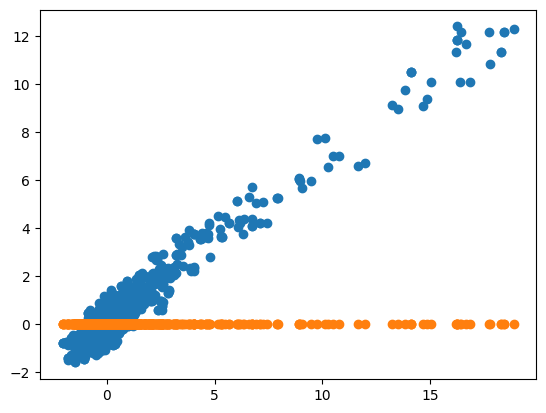

In [22]:
plt.scatter(Y[i1, :], Y[i2, :])
plt.scatter(projections[:, 0], projections[:, 1])
plt.show()

In [23]:
Y.shape

(4800, 1999)

In [50]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [229]:
@njit(parallel=True)
def get_distances(
    i: int, 
    Y: np.ndarray, 
    # ysum: np.ndarray, 
    projections: np.ndarray,
    dist_reg: np.ndarray,
    # dist_h: np.ndarray,
    # dist_v: np.ndarray,
):
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]

        if (u > 3.0).sum() < 10 or (v > 3.0).sum() < 10:
            dist_reg[j] = np.nan
            continue
        
        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]
        
        i_dot_j = np.dot(u, v)
        i_dot_i = np.dot(u, u)
        
        m = (i_dot_j - 1 / high_val_ixs.sum() * u.sum() * v.sum()) / (i_dot_i - 1 / high_val_ixs.sum() * u.sum()**2)
        # m = (i_dot_j - 1 / Y.shape[1] * ysum[i] * ysum[j]) / (i_dot_i - 1 / Y.shape[1] * ysum[i]**2)
        
        v1 = np.array([m, 1])

        # Step 1: Calculate means of x and y
        u_mean = np.mean(u)
        v_mean = np.mean(v)
        
        v1[0] += u_mean
        v1[1] += v_mean

        denom = np.sqrt(v1.sum())
        v1[0] = v1[0] / denom
        v1[1] = v1[1] / denom

        v1 /= np.sqrt(np.sum(v1**2))
        
        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v
        
        projections_pre = (X @ v1)
        
        projections[j, :u.size, 0] = projections_pre * v1[0]
        projections[j, :u.size, 1] = projections_pre * v1[1]

        orthogonal_distances = X - projections[j, :u.size]  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
        # orthogonal_distances = orthogonal_distances**2
        
        # # # Sum of orthogonal distances
        # sum_of_distances = np.sum(orthogonal_distances) / X.shape[0] / 1000

        dist_reg[j] = s**2

        # h = np.array([1, 0])
        # s = np.column_stack([u, v])
        # projections = (s @ h)[:, None] * h

In [230]:
# ysum = np.sum(Y, axis=1)
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))

In [245]:
get_distances(
    2510,
    Y,
    # ysum,
    projections,
    output_matrix
)

output_matrix = np.nan_to_num(output_matrix, nan=np.nanmax(output_matrix))
# output_matrix[output_matrix == 2e31] = output_matrix.max()

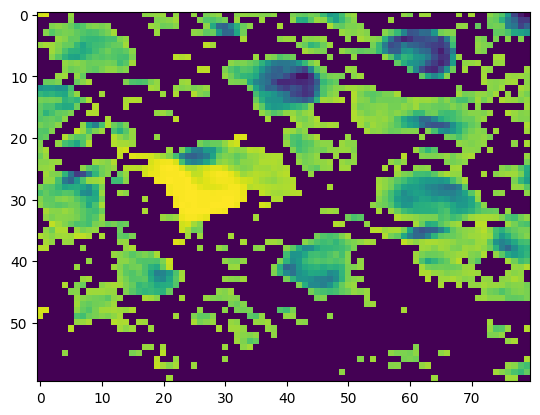

In [246]:
plt.imshow(unvec.transform(output_matrix), cmap="viridis_r")
plt.show()

In [247]:
output_matrix.min(), output_matrix.max()

(np.float64(1.5903446788881313e-11), np.float64(1715086.304732575))

In [176]:
projections.shape

(4800, 1999, 2)

In [177]:
std = unvec.transform(Y).std(axis=0)

In [248]:
iw = fpl.ImageWidget([std, np.zeros(std.shape)], cmap="viridis")

pixel_index_A = 0
projections = np.zeros((*Y.shape, 2))

pixel_A_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="magenta")
pixel_B_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="cyan")

@iw.managed_graphics[0].add_event_handler("double_click")
def update_distance_image(ev):
    global pixel_index_A
    global projections
    
    col, row = ev.pick_info["index"]

    i = np.ravel_multi_index((row, col), unvec.shape)
    
    pixel_index_A = i

    pixel_A_pt.data[0, 0] = col
    pixel_A_pt.data[0, 1] = row
    
    output_matrix = np.zeros((Y.shape[0],))
    projections = np.zeros((*Y.shape, 2))
    get_distances(
        i,
        Y,
        # ysum,
        projections,
        output_matrix
    )

    output_matrix = np.nan_to_num(output_matrix, nan=np.nanmax(output_matrix))
    
    iw.managed_graphics[1].data = unvec.transform(output_matrix)
    iw.reset_vmin_vmax()


fig_s = fpl.Figure(shape=(1, 2))

scatter_corr = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors=(1, 0.7, 0, 0.3), alpha=0.3)
scatter_proj = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors="r", alpha=0.3)
fig_s[0, 0].axes.colors = ("magenta", "cyan", "w")

line_p1 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="magenta", alpha=0.3)
line_p2 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="cyan", alpha=0.3)

selector_time = line_p1.add_linear_selector()

@iw.managed_graphics[1].add_event_handler("double_click")
def update_scatters(ev):
    u = Y[pixel_index_A]

    col, row = ev.pick_info["index"]

    j = np.ravel_multi_index((row, col), unvec.shape)
    v = Y[j]

    pixel_B_pt.data[0, 0] = col
    pixel_B_pt.data[0, 1] = row
    
    scatter_corr.data[:, :-1] = np.column_stack([u, v])
    scatter_proj.data[:, :-1] = projections[j]
    fig_s[0, 0].auto_scale(maintain_aspect=False)

    line_p1.data[:, 1] = u
    line_p2.data[:, 1] = v
    fig_s[0, 1].auto_scale(maintain_aspect=False)

@selector_time.add_event_handler("selection")
def update_selected_time(ev):
    t = ev.get_selected_index()
    scatter_corr.colors = (1, 0.7, 0, 0.3)
    scatter_corr.sizes = 4
    
    scatter_corr.colors[t] = "w"
    scatter_corr.sizes[t] = 20


iw.cmap = ["viridis", "viridis_r"]

VBox([iw.show(), fig_s.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

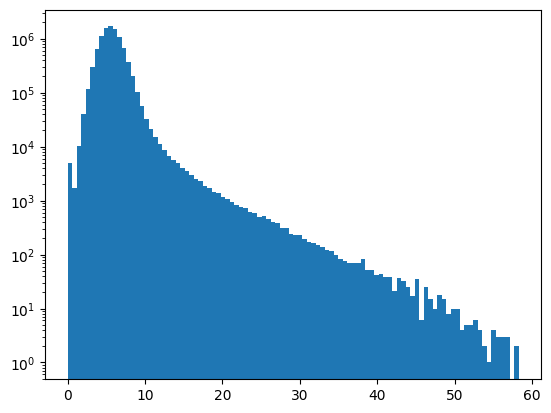

In [32]:
plt.hist(filt_movie.ravel(), bins=100)
plt.semilogy()
plt.show()

In [33]:
iw.managed_graphics[1].vmax = np.percentile(iw.managed_graphics[1].data[:], 3)

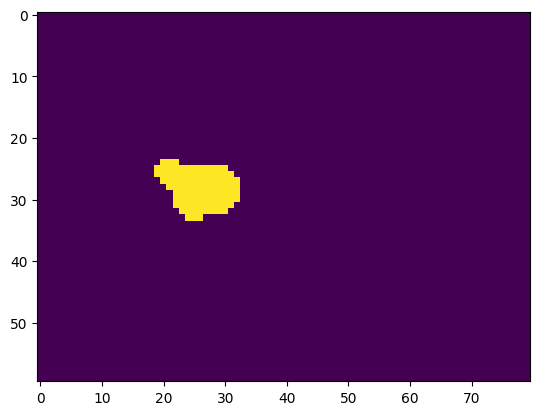

In [34]:
plt.imshow(iw.managed_graphics[1].data[:] < np.percentile(iw.managed_graphics[1].data[:], 2))

In [35]:
np.percentile(iw.managed_graphics[1].data[:], 3)

np.float32(3090294.0)

In [36]:
i_col, i_row, _ =  pixel_A_pt.data[0]
i_col, i_row

(np.float32(23.0), np.float32(29.0))

In [37]:
j_col, j_row, _ = pixel_B_pt.data[0]
j_col, j_row

(np.float32(21.0), np.float32(25.0))

# Plot time series of the two pixels, linear region selector to highlight scatter point
# click on scatter point, set linear region selector timepoint

In [38]:
Y.shape

(4800, 1999)

In [39]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [53]:
for i in tqdm(range(Y.shape[0])):
    output_matrix = np.zeros((Y.shape[0],))
    get_distances(
        i,
        Y,
        ysum,
        projections,
        output_matrix
    )
    dist_cov[i] = output_matrix

100%|███████████████████████████████████████████████████████████████████████████████████████| 4800/4800 [01:06<00:00, 72.63it/s]


RFBOutputContext()

JupyterWgpuCanvas(css_height='400px', css_width='700px')
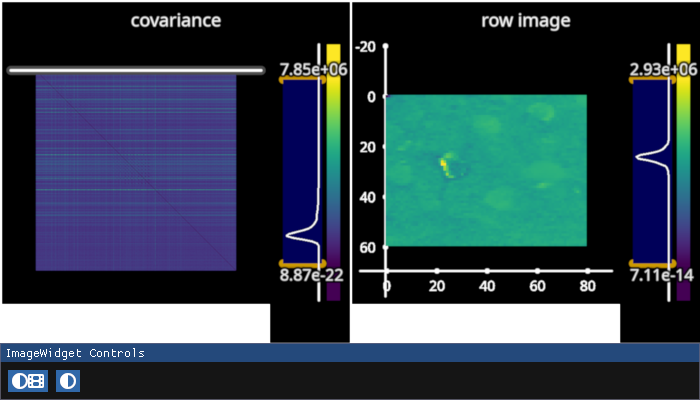

In [54]:
# dist_cov -= dist_cov.max()
# dist_cov = np.abs(dist_cov)

img = unvec.transform(dist_cov[0])

figure_kwargs = {"size": (700, 400), "controller_ids": [[0, 1]]}
iw_cov = fpl.ImageWidget(
    data=[dist_cov, img],
    names=["covariance", "row image"],
    figure_kwargs=figure_kwargs,
)

iw_cov.cmap = ["viridis", "viridis"]

selector_cov = iw_cov.managed_graphics[0].add_linear_selector(axis="y")

@selector_cov.add_event_handler("selection")
def update_img(ev):
    ix = ev.get_selected_index()
    img = unvec.transform(dist_cov[ix])
    iw_cov.managed_graphics[1].data = img

iw_cov.show()

In [109]:
selector_cov.selection = 4532

In [57]:
dist_cov.shape

(4800, 4800)

In [58]:
a = dist_cov / np.max(dist_cov)

In [65]:
np.nan

nan

In [67]:
np.fill_diagonal(a, val=np.nan)

In [194]:
eps = 0.08

In [212]:
pts = np.unique(np.where((a < eps) & (Y.max(axis=1) > 10)))

In [213]:
row_ixs, col_ixs = np.unravel_index(pts, unvec.shape)

iw_movie = fpl.ImageWidget(std, cmap="viridis")
iw_movie.figure[0, 0].add_scatter(np.column_stack([col_ixs, row_ixs]), colors=(1, 0, 0, 0.5), sizes=5)

tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  movie[:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

VBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [214]:
pts.size

1275

In [224]:
dist_cov_imp = dist_cov[pts][:, pts]
dist_cov_imp.shape

(1275, 1275)

In [286]:
dist_cov - dist_cov.T

array([[      0.   ,   87469.875,  244418.5  , ...,  229979.5  ,
         248889.   ,  292061.62 ],
       [ -87469.875,       0.   ,  106096.31 , ...,   60346.5  ,
          84321.125,  129777.25 ],
       [-244418.5  , -106096.31 ,       0.   , ...,  -23510.5  ,
          -5076.25 ,   34384.375],
       ...,
       [-229979.5  ,  -60346.5  ,   23510.5  , ...,       0.   ,
          41011.875,   71398.44 ],
       [-248889.   ,  -84321.125,    5076.25 , ...,  -41011.875,
              0.   ,   13833.875],
       [-292061.62 , -129777.25 ,  -34384.375, ...,  -71398.44 ,
         -13833.875,       0.   ]], dtype=float32)

In [285]:
from sklearn.manifold import MDS

se = MDS(n_components=3, dissimilarity="precomputed")
e = se.fit_transform(dist_cov_imp)

ValueError: Array must be symmetric

In [280]:
e.shape

(1275, 5)

In [281]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=20)
gmm.fit(e)
labels = np.zeros((Y.shape[0], 20))
labels[:] = 0
labels[pts] = gmm.predict_proba(e)

In [282]:
labels.shape

(4800, 20)

RFBOutputContext()

JupyterWgpuCanvas()
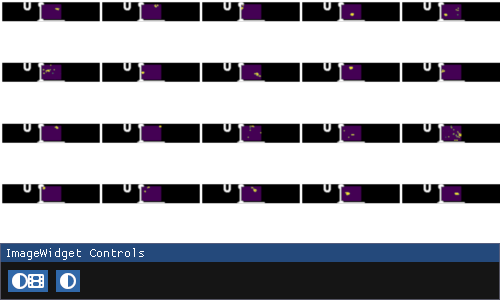

In [283]:
fpl.ImageWidget([a for a in unvec.transform(labels)], cmap="viridis", histogram_widget=False).show()

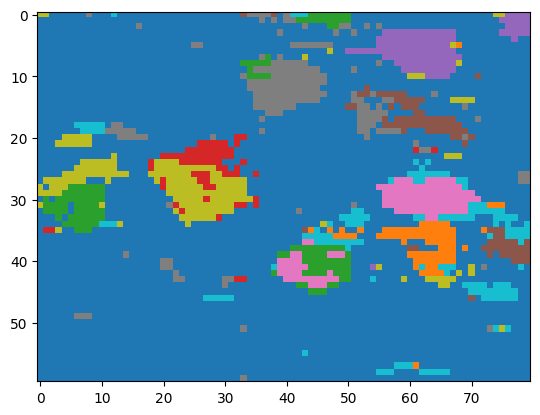

In [255]:
plt.imshow(unvec.transform(labels), cmap="tab10")

RFBOutputContext()

JupyterWgpuCanvas()
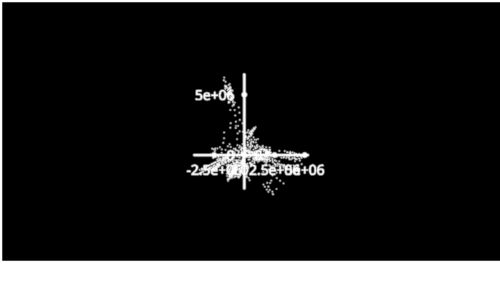

In [243]:
fig = fpl.Figure(cameras="3d")
fig[0, 0].add_scatter(e)
fig.show()

In [181]:
labels.shape

(4800,)

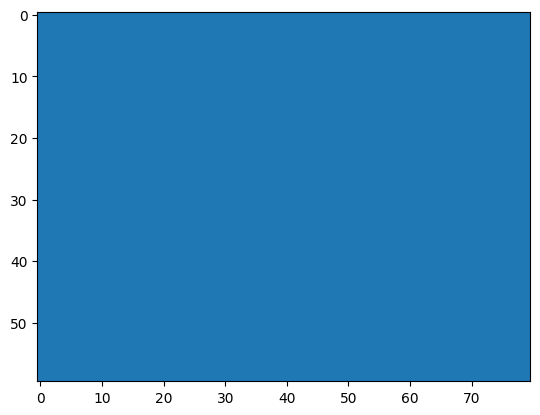

In [184]:
plt.imshow(unvec.transform(labels), cmap="tab10")

In [43]:
Y.shape

(4800, 1999)

In [44]:
clusters = np.zeros((100, Y.shape[0]), dtype=np.int32)

In [47]:
for i in tqdm(range(1500, 3000)):
    # see if this pixel is never active
    if np.count_nonzero(Y[i] > 5) < 3:
        continue
    
    threshold = np.percentile(dist_cov[i], 3)

    # does this pixel already belong to any existing cluster(s)
    cluster_memberships = np.where(clusters[:, i] != 0)[0]
    if cluster_memberships.size == 0:
        # create new cluster index for this pixel and keep if matches are found
        for n in range(clusters.shape[0]):
            if (clusters[n, :] == 0).all():
                break
                
        membership_indices = np.array([n])
    else:
        membership_indices = cluster_memberships
    
    for j in range(1100, 2200):
        # check if pixel is active
        if np.count_nonzero(Y[j] > 5) < 3:
            continue

        if dist_cov[i, j] < threshold:
            # add i and j to this cluster
            clusters[membership_indices, j] = 1
            flag_match = True
            
    if flag_match:
        clusters[membership_indices, i] = 1

100%|███████████████████████████████████████████████████████████████████| 1500/1500 [00:01<00:00, 1236.66it/s]


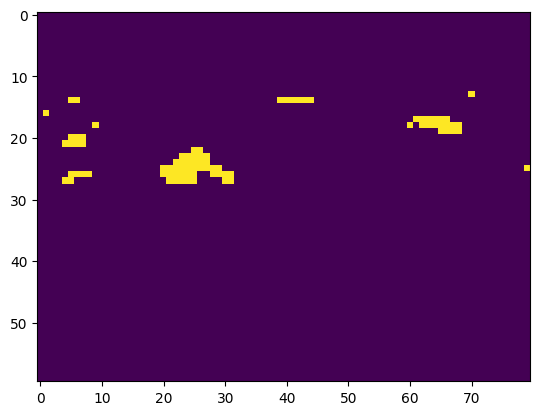

In [54]:
plt.imshow(unvec.transform(clusters[0]))

In [55]:
from sklearn.cluster import SpectralClustering

In [62]:
sc = SpectralClustering(n_clusters=15, affinity="precomputed", assign_labels="kmeans")

In [63]:
sc.fit_predict(dist_cov)

/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)


array([1, 1, 1, ..., 1, 1, 5], dtype=int32)

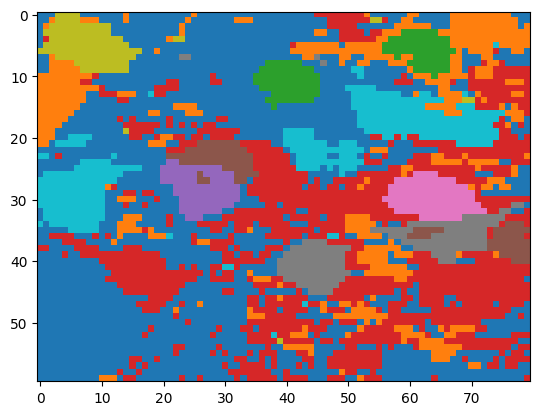

In [64]:
plt.imshow(unvec.transform(sc.labels_), cmap="tab10")

In [51]:
from sklearn.metrics import davies_bouldin_score

In [57]:
scores = list()

for n in range(2, 20):
    sc = SpectralClustering(n_clusters=n, affinity="precomputed", assign_labels="cluster_qr")
    sc.fit_predict(dist_cov)
    score = davies_bouldin_score(Y, sc.labels_)
    scores.append(score)

/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)
/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)
/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)
/home/kushal/venvs/fpl/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:310: UserWarning: Array is not symmetric, and will be converted to symmetric by average with its transpose.
  adjacency = check_symmetric(adjacency)
/home/kushal/venvs/fpl/lib/python3.1

([<matplotlib.axis.XTick at 0x7eff25d41310>,
 [Text(0, 0, '2'),
  Text(1, 0, '3'),
  Text(2, 0, '4'),
  Text(3, 0, '5'),
  Text(4, 0, '6'),
  Text(5, 0, '7'),
  Text(6, 0, '8'),
  Text(7, 0, '9'),
  Text(8, 0, '10'),
  Text(9, 0, '11'),
  Text(10, 0, '12'),
  Text(11, 0, '13'),
  Text(12, 0, '14'),
  Text(13, 0, '15'),
  Text(14, 0, '16'),
  Text(15, 0, '17'),
  Text(16, 0, '18'),
  Text(17, 0, '19')])

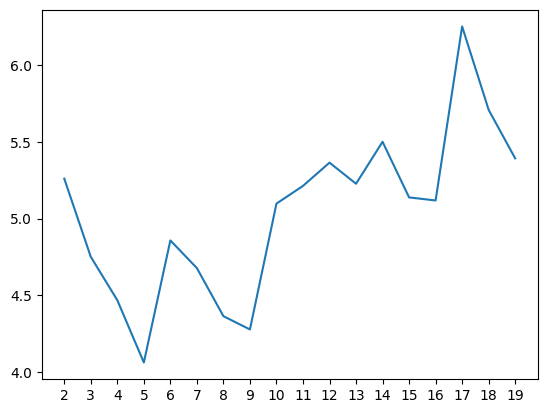

In [60]:
plt.plot(scores)
plt.xticks(range(0, 18), range(2, 20))